### Business Insights and Strategic Recommendations

#### Objective

The purpose of this notebook is to translate the analytical findings into meaningful business insights and actionable recommendations.

The focus is on understanding vehicle sales patterns, identifying high-performing segments, and providing strategic recommendations based on the results of the exploratory analysis and regression modeling.

#### Workflow

- Load data
- Price Segmentation Analysis
- Wheelbase Segmentation Analysis
- Top selling models 
- Key Findings and Strategic Recommendations

#### 1. Loading Data

In [1]:
# Import necessary libraries 
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load cleaned dataset
df = pd.read_csv("../data/processed/car_sales_clean.csv")

# Restore important data types
df["Latest_Launch"] = pd.to_datetime(df["Latest_Launch"])

cat_cols = ["Manufacturer", "Model", "Vehicle_type"]
df[cat_cols] = df[cat_cols].astype("category")

df.head()

,Manufacturer,Model,Sales_in_thousands,__year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
0,Acura,Integra,16.919,16.360,Passenger,21.500,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2012-02-02,58.280150
1,Acura,TL,39.384,19.875,Passenger,28.400,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,2011-06-03,91.370778
2,Acura,CL,14.114,18.225,Passenger,22.799,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,2012-01-04,72.030917
3,Acura,RL,8.588,29.725,Passenger,42.000,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2011-03-10,91.389779
4,Audi,A4,20.397,22.255,Passenger,23.990,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,2011-10-08,62.777639


#### 2. Price Segmentation Analysis

Vehicle pricing plays an important role in sales performance.

To better understand customer purchasing behavior, vehicles are divided into three price segments:

- Budget
- Mid-Range
- Premium

This analysis helps identify which price segment generates the highest average sales.

In [2]:
# Create price segments

df["Price_Category"] = pd.cut(
    df["Price_in_thousands"],
    bins=[0, 20, 40, 100],
    labels=["Budget", "Mid-Range", "Premium"]
)

# Check distribution

df["Price_Category"].value_counts()

Price_Category
Mid-Range    78
Budget       55
Premium      24
Name: count, dtype: int64

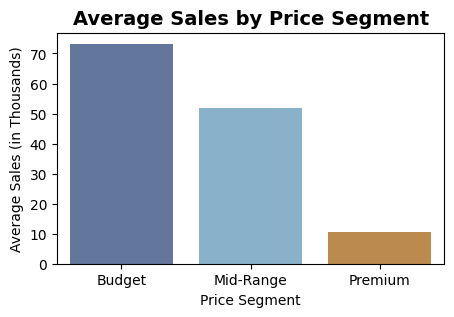

In [3]:
# Average sales by price category

sales_by_price = (
    df.groupby("Price_Category", observed=False)["Sales_in_thousands"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(5, 3))

sns.barplot(
    x=sales_by_price.index,
    y=sales_by_price.values,
    hue=sales_by_price.index,
    palette=["#5875A4", "#7FB3D5", "#CC8C3C"],
    legend=False
)

plt.title(
    "Average Sales by Price Segment",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Price Segment")
plt.ylabel("Average Sales (in Thousands)")

plt.show()

#### Business Insight

Customers are more likely to purchase affordable vehicles, resulting in higher sales for the Budget segment. Premium vehicles, although higher in value, attract a smaller customer base and therefore achieve lower sales volumes.

#### 3. Wheelbase Segmentation Analysis

The regression model identified Wheelbase as a significant positive predictor of vehicle sales.

To better understand this relationship, vehicles are grouped into wheelbase segments and their average sales performance is compared.

This analysis helps determine whether larger vehicles generally achieve higher sales volumes.

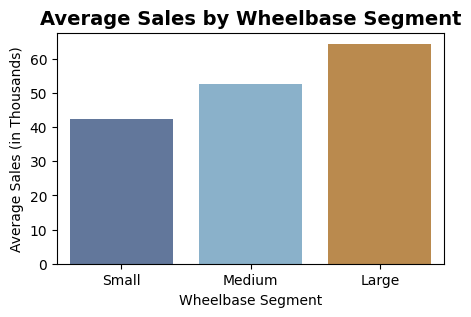

In [4]:
# Create wheelbase segments

df["Wheelbase_Category"] = pd.qcut(
    df["Wheelbase"],
    q=3,
    labels=["Small", "Medium", "Large"]
)

# Average sales by wheelbase category

sales_by_wheelbase = (
    df.groupby("Wheelbase_Category", observed=False)["Sales_in_thousands"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(5, 3))

sns.barplot(
    x=sales_by_wheelbase.index,
    y=sales_by_wheelbase.values,
    hue=sales_by_wheelbase.index,
    palette=["#5875A4", "#7FB3D5", "#CC8C3C"],
    legend=False
)

plt.title(
    "Average Sales by Wheelbase Segment",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Wheelbase Segment")
plt.ylabel("Average Sales (in Thousands)")

plt.show()

#### Observations

- Vehicles in the **Large wheelbase segment** achieve the highest average sales volumes.

- Average sales increase steadily from Small to Medium to Large wheelbase categories.

- The results support the regression analysis, which identified Wheelbase as a significant positive predictor of sales.

- Larger vehicles appear to be more popular among customers, leading to stronger sales performance.

#### 4. Top 10 Selling Vehicle Models

This analysis identifies the best-selling vehicle models in the dataset and the manufacturers behind them.

Understanding which models generate the highest sales can help identify successful product strategies and market preferences.

In [5]:
# Top 10 selling vehicle models

top_models = (
    df.groupby(["Manufacturer", "Model"], observed=False)["Sales_in_thousands"]
      .sum()
      .reset_index()
      .sort_values(by="Sales_in_thousands", ascending=False)
      .head(10)
)

top_models.rename(
    columns={
        "Manufacturer": "Manufacturer",
        "Model": "Vehicle Model",
        "Sales_in_thousands": "Sales (Thousands)"
    },
    inplace=True
)

top_models.reset_index(drop=True, inplace=True)

top_models.index += 1

display(top_models)

,Manufacturer,Vehicle Model,Sales (Thousands)
1,Ford,F-Series,540.561
2,Ford,Explorer,276.747
3,Toyota,Camry,247.994
4,Ford,Taurus,245.815
5,Honda,Accord,230.902
6,Dodge,Ram Pickup,227.061
7,Ford,Ranger,220.650
8,Honda,Civic,199.685
9,Dodge,Caravan,181.749
10,Ford,Focus,175.670


##### Observations

- Ford dominates the list, with **five of the top ten best-selling vehicle models**, highlighting its strong market presence.

- The **Ford F-Series** is the highest-selling vehicle model by a large margin, achieving more than 540 thousand sales and significantly outperforming all other models.

- Honda, Toyota, and Dodge also have successful models in the top ten, indicating strong demand across multiple manufacturers.

- Pickup trucks, family vehicles, and mid-sized sedans such as the F-Series, Explorer, Camry, Accord, and Caravan appear among the top-selling models, suggesting strong customer demand in these vehicle segments.

- The results indicate that a small number of highly successful vehicle models contribute substantially to overall manufacturer sales performance.

#### 5. Key Findings

##### From Exploratory Data Analysis (EDA)

- Vehicle sales are highly skewed, with a small number of vehicle models generating exceptionally high sales.

- Higher-priced vehicles generally achieve lower sales volumes.

- Larger vehicles tend to achieve higher sales volumes.

- Vehicle type influences sales performance, with Cars showing higher average sales.

##### From Regression Analysis

- Price_in_thousands is a statistically significant predictor of sales.

- Wheelbase is a statistically significant predictor of sales.

- Higher vehicle prices are associated with lower sales volumes.

- Larger wheelbases are associated with higher sales volumes.

##### From Business Analysis

- Budget vehicles achieve the highest average sales.

- Premium vehicles achieve the lowest average sales.

- Vehicles with larger wheelbases consistently outperform smaller vehicles in terms of average sales.


#### 6. Strategic Recommendations

##### 1. Focus on Affordable Vehicle Segments

The price segmentation analysis showed that Budget vehicles achieve the highest average sales volumes.

**Recommendation:** Maintain competitive pricing strategies and expand offerings in the budget and mid-range segments to attract a larger customer base.

---

##### 2. Prioritize Vehicle Size and Comfort

The wheelbase segmentation and regression analysis showed that vehicles with larger wheelbases tend to achieve higher sales.

**Recommendation:** Consider designing vehicles with larger wheelbases and improved interior space to better align with customer preferences.

---

##### 3. Balance Price and Vehicle Features

While larger vehicles perform well, higher vehicle prices are associated with lower sales volumes.

**Recommendation:** Offer spacious vehicles at competitive price points to maximize both customer appeal and sales performance.

---

##### 4. Focus on High-Demand Product Segments

Sales are concentrated among a limited number of vehicle models and manufacturers.

**Recommendation:** Identify and invest in vehicle segments with proven market demand while regularly reviewing underperforming products.

---

##### 5. Improve Future Sales Forecasting

The regression model explained approximately 25% of the variation in vehicle sales, indicating that additional factors influence purchasing decisions.

**Recommendation:** Incorporate variables such as brand reputation, marketing activities, customer preferences, and economic conditions in future analyses to improve prediction accuracy.

### Key Takeaway

Customers appear to prefer vehicles that offer a combination of affordability and larger vehicle dimensions. Manufacturers can improve sales performance by maintaining competitive pricing while delivering vehicles that provide greater space and comfort.